# Phase 1 – Baseline: Data Quality & Normal-Only Sensor Statistics
**Project:** Predictive Maintenance & Anomaly Detection (DEPI)

This notebook does three things:
1. **Validates** the processed dataset (schema, dtypes, missing / infinite values, timestamp order & duplicates).
2. **Profiles** each sensor and writes `baseline_quality_report.csv`.
3. **Computes the reference baseline** from **normal readings only** (`ground_truth == 0`) and writes `sensor_baseline.csv`, used downstream by Z-score, Isolation Forest and XAI steps.

> Edit only the **CONFIG** cell. Everything else is driven by it.

## 1. Imports & logging

In [1]:
import json
import logging
from pathlib import Path

import numpy as np
import pandas as pd

logging.basicConfig(
    level=logging.INFO,
    format="%(asctime)s | %(levelname)-8s | %(message)s",
    datefmt="%H:%M:%S",
    force=True,  # make re-running the cell safe inside Jupyter
)
log = logging.getLogger("baseline")

## 2. CONFIG
- `SENSORS = None` → sensors are **auto-detected** (numeric columns that are not timestamp / label / id columns).
- A sensor is treated as **digital/binary** if it has at most `DIGITAL_MAX_UNIQUE` distinct values (default 2) in the normal data.

In [3]:
CONFIG = {
    # --- paths ---
    "DATA_PATH": Path(r"C:\Users\compu import\Desktop\TEST\data_labeled.csv"),   # <- change to your file
    "OUTPUT_DIR": Path("outputs/metrics"),
   
    # --- column names ---
    "TIMESTAMP_COL": "timestamp",     # set to None if the dataset has no timestamp
    "LABEL_COL": "ground_truth",      # 0 = normal, 1 = anomaly/failure
    "ID_COL": None,                   # e.g. "engine_id" / "unit" if data has several machines
    "SENSORS": None,                  # None = auto-detect, or e.g. ["s1", "s2", ...]
    "EXTRA_EXCLUDE_COLS": ["segment"],         # other non-sensor columns (e.g. "cycle", "rul")

    # --- behaviour ---
    "DIGITAL_MAX_UNIQUE": 2,          # <= this many distinct values => digital/binary sensor
    "MIN_NORMAL_ROWS": 30,            # fail if fewer normal rows than this
    "STRICT": False,                  # True => raise on integrity problems instead of warning
}

OUT_QUALITY = CONFIG["OUTPUT_DIR"] / "baseline_quality_report.csv"
OUT_BASELINE = CONFIG["OUTPUT_DIR"] / "sensor_baseline.csv"
OUT_SUMMARY = CONFIG["OUTPUT_DIR"] / "baseline_integrity_summary.json"

## 3. Loading & validation functions

In [4]:
class DataValidationError(Exception):
    """Raised when the dataset cannot be used for baseline computation."""


def load_data(path: Path) -> pd.DataFrame:
    """Load a CSV file with clear errors for the common failure modes."""
    path = Path(path)
    if not path.exists():
        raise FileNotFoundError(f"Dataset not found: {path.resolve()}")
    try:
        df = pd.read_csv(path)
    except pd.errors.EmptyDataError as exc:
        raise DataValidationError(f"File is empty: {path}") from exc
    if df.empty:
        raise DataValidationError(f"File has no rows: {path}")
    log.info("Loaded %s -> %d rows x %d columns", path.name, *df.shape)
    return df


def infer_sensors(df: pd.DataFrame, cfg: dict) -> list:
    """Return the sensor column list (explicit from config, else auto-detected)."""
    non_sensor = {cfg["TIMESTAMP_COL"], cfg["LABEL_COL"], cfg["ID_COL"], *cfg["EXTRA_EXCLUDE_COLS"]}
    non_sensor.discard(None)

    if cfg["SENSORS"]:
        missing = [c for c in cfg["SENSORS"] if c not in df.columns]
        if missing:
            raise DataValidationError(f"Configured sensors missing from data: {missing}")
        sensors = list(cfg["SENSORS"])
    else:
        sensors = [c for c in df.columns
                   if c not in non_sensor and pd.api.types.is_numeric_dtype(df[c])]
        if not sensors:
            raise DataValidationError("No numeric sensor columns found. Set CONFIG['SENSORS'].")
        log.info("Auto-detected %d sensors: %s", len(sensors), sensors)

    non_numeric = [c for c in sensors if not pd.api.types.is_numeric_dtype(df[c])]
    if non_numeric:
        raise DataValidationError(f"Sensor columns must be numeric, got non-numeric: {non_numeric}")
    return sensors


def validate_schema(df: pd.DataFrame, cfg: dict) -> None:
    """Check required columns exist and the label column is a clean 0/1 field."""
    required = [cfg["LABEL_COL"]] + ([cfg["TIMESTAMP_COL"]] if cfg["TIMESTAMP_COL"] else []) \
               + ([cfg["ID_COL"]] if cfg["ID_COL"] else [])
    missing = [c for c in required if c not in df.columns]
    if missing:
        raise DataValidationError(f"Required columns missing: {missing}. Available: {list(df.columns)}")

    label = df[cfg["LABEL_COL"]]
    if label.isna().any():
        raise DataValidationError(f"'{cfg['LABEL_COL']}' contains {int(label.isna().sum())} missing values.")
    bad = set(pd.unique(label)) - {0, 1}
    if bad:
        raise DataValidationError(f"'{cfg['LABEL_COL']}' must be 0/1, found other values: {sorted(bad)}")
    log.info("Schema OK. Label distribution: %s", label.value_counts().sort_index().to_dict())


def _problem(msg: str, strict: bool) -> None:
    """Warn, or raise when STRICT is on."""
    if strict:
        raise DataValidationError(msg)
    log.warning(msg)


def check_integrity(df: pd.DataFrame, sensors: list, cfg: dict) -> dict:
    """Run integrity checks and return a JSON-serialisable summary.

    Checks: dtypes, missing values, +/-inf, duplicated rows, and timestamp
    parseability / duplicates / ordering (per ID group if ID_COL is set).
    """
    strict = cfg["STRICT"]
    summary = {"rows": int(len(df)), "columns": int(df.shape[1]), "sensors": sensors}

    # dtypes
    summary["dtypes"] = {c: str(df[c].dtype) for c in sensors}

    # missing + infinite
    miss = df[sensors].isna().sum()
    inf = np.isinf(df[sensors]).sum()
    summary["missing_total"] = int(miss.sum())
    summary["inf_total"] = int(inf.sum())
    if miss.sum():
        _problem(f"Missing values in sensors: {miss[miss > 0].to_dict()}", strict)
    if inf.sum():
        _problem(f"Infinite values in sensors: {inf[inf > 0].to_dict()}", strict)

    # fully duplicated rows
    n_dup_rows = int(df.duplicated().sum())
    summary["duplicate_rows"] = n_dup_rows
    if n_dup_rows:
        _problem(f"{n_dup_rows} fully duplicated rows.", strict)

    # timestamps
    ts_col = cfg["TIMESTAMP_COL"]
    if ts_col is None:
        log.warning("No timestamp column configured - skipping timestamp checks.")
        summary["timestamp"] = "skipped"
    else:
        ts = pd.to_datetime(df[ts_col], errors="coerce")
        n_bad = int(ts.isna().sum())
        ts_info = {"unparseable": n_bad}
        if n_bad:
            _problem(f"{n_bad} timestamps could not be parsed.", strict)

        id_col = cfg["ID_COL"]
        keys = [id_col, ts_col] if id_col else [ts_col]
        tmp = df[[c for c in keys if c != ts_col]].copy() if id_col else pd.DataFrame(index=df.index)
        tmp[ts_col] = ts
        n_dup_ts = int(tmp.duplicated().sum())
        ts_info["duplicate_timestamps"] = n_dup_ts
        if n_dup_ts:
            _problem(f"{n_dup_ts} duplicate timestamps" + (f" (per {id_col})." if id_col else "."), strict)

        grouped = tmp.groupby(id_col)[ts_col] if id_col else [(None, tmp[ts_col])]
        n_unordered = sum(0 if s.dropna().is_monotonic_increasing else 1 for _, s in grouped)
        ts_info["unordered_groups"] = int(n_unordered)
        if n_unordered:
            _problem("Timestamps are not sorted ascending" + (f" in {n_unordered} {id_col} group(s)." if id_col else "."), strict)

        if ts.notna().any():
            ts_info["start"], ts_info["end"] = str(ts.min()), str(ts.max())
        summary["timestamp"] = ts_info

    log.info("Integrity checks finished.")
    return summary

## 4. Data quality report
One row per sensor over the **full** dataset (normal + anomalous): counts, missing, infinite, unique values, zero fraction.

In [5]:
def build_quality_report(df: pd.DataFrame, sensors: list, digital_max_unique: int = 2) -> pd.DataFrame:
    """Per-sensor profile: row count, missing, inf, unique values, zero fraction."""
    n = len(df)
    rows = []
    for s in sensors:
        col = df[s]
        finite = col.replace([np.inf, -np.inf], np.nan).dropna()
        n_unique = int(finite.nunique())
        rows.append({
            "sensor": s,
            "dtype": str(col.dtype),
            "n_rows": n,
            "n_missing": int(col.isna().sum()),
            "missing_pct": round(100 * col.isna().mean(), 4),
            "n_inf": int(np.isinf(col).sum()),
            "n_unique": n_unique,
            "zero_fraction": float((finite == 0).mean()) if len(finite) else np.nan,
            "is_constant": n_unique <= 1,
            "sensor_type": "digital" if n_unique <= digital_max_unique else "analogue",
        })
    return pd.DataFrame(rows)

## 5. Strict baseline (normal data only)
Only rows with `ground_truth == 0` are used, so failure readings cannot inflate the limits.

| Column | Meaning |
|---|---|
| `n, mean, std, median, Q1, Q3, IQR, min, max, p01, p99` | standard descriptive statistics |
| `MAD` | raw median absolute deviation |
| `MAD_scaled` | `1.4826 * MAD` - comparable to `std` for normal data (robust z-scores) |
| `sensor_type` | `analogue` or `digital` (binary) |
| `zscore_usable` | `False` for constant sensors or digital sensors (z-score not meaningful) |
| `on_fraction` | digital sensors only: share of readings equal to the higher value |

In [6]:
MAD_SCALE = 1.4826  # makes MAD a consistent estimator of std under normality


def compute_baseline(df: pd.DataFrame, sensors: list, cfg: dict) -> pd.DataFrame:
    """Compute reference statistics per sensor from normal rows only (label == 0)."""
    normal = df[df[cfg["LABEL_COL"]] == 0]
    n_total, n_normal = len(df), len(normal)
    if n_normal < cfg["MIN_NORMAL_ROWS"]:
        raise DataValidationError(
            f"Only {n_normal} normal rows (< MIN_NORMAL_ROWS={cfg['MIN_NORMAL_ROWS']}); baseline unreliable.")
    log.info("Using %d / %d rows (%.1f%%) as normal baseline data.", n_normal, n_total, 100 * n_normal / n_total)

    rows = []
    for s in sensors:
        x = normal[s].replace([np.inf, -np.inf], np.nan).dropna()
        if x.empty:
            log.warning("Sensor %s has no valid normal readings - filled with NaN.", s)
            rows.append({"sensor": s, "n": 0, "sensor_type": "unknown", "zscore_usable": False})
            continue

        q1, q3 = x.quantile(0.25), x.quantile(0.75)
        med = x.median()
        mad = float((x - med).abs().median())
        std = float(x.std(ddof=1)) if len(x) > 1 else 0.0
        n_unique = int(x.nunique())
        is_digital = n_unique <= cfg["DIGITAL_MAX_UNIQUE"]
        is_constant = n_unique <= 1 or std == 0.0

        rows.append({
            "sensor": s,
            "n": int(len(x)),
            "mean": float(x.mean()),
            "std": std,
            "median": float(med),
            "Q1": float(q1),
            "Q3": float(q3),
            "IQR": float(q3 - q1),
            "MAD": mad,
            "MAD_scaled": MAD_SCALE * mad,
            "min": float(x.min()),
            "max": float(x.max()),
            "p01": float(x.quantile(0.01)),
            "p99": float(x.quantile(0.99)),
            "n_unique": n_unique,
            "sensor_type": "digital" if is_digital else "analogue",
            "on_fraction": float((x == x.max()).mean()) if is_digital and n_unique == 2 else np.nan,
            "zscore_usable": bool(not is_digital and not is_constant),
        })
        if is_constant:
            log.warning("Sensor %s is constant in normal data (std=0): z-scores undefined.", s)

    base = pd.DataFrame(rows).set_index("sensor")
    return base


def save_outputs(quality: pd.DataFrame, baseline: pd.DataFrame, summary: dict, cfg: dict) -> None:
    """Write the three output artefacts."""
    cfg["OUTPUT_DIR"].mkdir(parents=True, exist_ok=True)
    quality.to_csv(OUT_QUALITY, index=False)
    baseline.to_csv(OUT_BASELINE)  # index = sensor
    with open(OUT_SUMMARY, "w") as f:
        json.dump(summary, f, indent=2, default=str)
    for p in (OUT_QUALITY, OUT_BASELINE, OUT_SUMMARY):
        log.info("saved: %s", p)

## 6. Run the pipeline

In [7]:
def run_baseline(cfg: dict = CONFIG):
    df = load_data(cfg["DATA_PATH"])
    validate_schema(df, cfg)
    sensors = infer_sensors(df, cfg)

    summary = check_integrity(df, sensors, cfg)
    quality = build_quality_report(df, sensors, cfg["DIGITAL_MAX_UNIQUE"])
    baseline = compute_baseline(df, sensors, cfg)

    summary["normal_rows"] = int((df[cfg["LABEL_COL"]] == 0).sum())
    summary["anomaly_rows"] = int((df[cfg["LABEL_COL"]] == 1).sum())
    save_outputs(quality, baseline, summary, cfg)
    return df, quality, baseline, summary


df, quality, baseline, summary = run_baseline()

00:57:13 | INFO     | Loaded data_labeled.csv -> 1516948 rows x 18 columns
00:57:13 | INFO     | Schema OK. Label distribution: {0: 1486994, 1: 29954}
00:57:13 | INFO     | Auto-detected 15 sensors: ['TP2', 'TP3', 'H1', 'DV_pressure', 'Reservoirs', 'Oil_temperature', 'Motor_current', 'COMP', 'DV_eletric', 'Towers', 'MPG', 'LPS', 'Pressure_switch', 'Oil_level', 'Caudal_impulses']
00:57:19 | INFO     | Integrity checks finished.
00:57:21 | INFO     | Using 1486994 / 1516948 rows (98.0%) as normal baseline data.
00:57:27 | INFO     | saved: outputs\metrics\baseline_quality_report.csv
00:57:27 | INFO     | saved: outputs\metrics\sensor_baseline.csv
00:57:27 | INFO     | saved: outputs\metrics\baseline_integrity_summary.json


In [8]:
def run_baseline(cfg: dict = CONFIG):
    df = load_data(cfg["DATA_PATH"])
    validate_schema(df, cfg)
    sensors = infer_sensors(df, cfg)

    summary = check_integrity(df, sensors, cfg)
    quality = build_quality_report(df, sensors, cfg["DIGITAL_MAX_UNIQUE"])
    baseline = compute_baseline(df, sensors, cfg)

    summary["normal_rows"] = int((df[cfg["LABEL_COL"]] == 0).sum())
    summary["anomaly_rows"] = int((df[cfg["LABEL_COL"]] == 1).sum())
    save_outputs(quality, baseline, summary, cfg)
    return df, quality, baseline, summary


df, quality, baseline, summary = run_baseline()

00:59:07 | INFO     | Loaded data_labeled.csv -> 1516948 rows x 18 columns
00:59:07 | INFO     | Schema OK. Label distribution: {0: 1486994, 1: 29954}
00:59:07 | INFO     | Auto-detected 15 sensors: ['TP2', 'TP3', 'H1', 'DV_pressure', 'Reservoirs', 'Oil_temperature', 'Motor_current', 'COMP', 'DV_eletric', 'Towers', 'MPG', 'LPS', 'Pressure_switch', 'Oil_level', 'Caudal_impulses']
00:59:14 | INFO     | Integrity checks finished.
00:59:16 | INFO     | Using 1486994 / 1516948 rows (98.0%) as normal baseline data.
00:59:22 | INFO     | saved: outputs\metrics\baseline_quality_report.csv
00:59:22 | INFO     | saved: outputs\metrics\sensor_baseline.csv
00:59:22 | INFO     | saved: outputs\metrics\baseline_integrity_summary.json


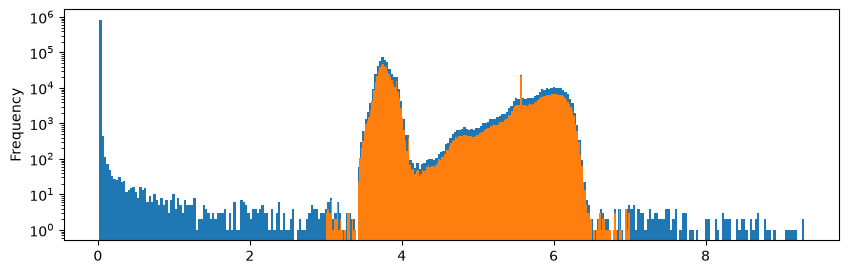

In [9]:
import matplotlib.pyplot as plt
df["Motor_current"].plot.hist(bins=300, logy=True, figsize=(10,3))
df.loc[df["Motor_current"].between(3, 7), "Motor_current"].plot.hist(bins=200, figsize=(10,3))
plt.show()

## 7. Inspect results

In [10]:
print("Integrity summary:")
print(json.dumps({k: v for k, v in summary.items() if k not in ("dtypes", "sensors")}, indent=2, default=str))
quality

Integrity summary:
{
  "rows": 1516948,
  "columns": 18,
  "missing_total": 0,
  "inf_total": 0,
  "duplicate_rows": 0,
  "timestamp": {
    "unparseable": 0,
    "duplicate_timestamps": 0,
    "unordered_groups": 0,
    "start": "2020-02-01 00:00:00",
    "end": "2020-09-01 03:59:50"
  },
  "normal_rows": 1486994,
  "anomaly_rows": 29954
}


,sensor,dtype,n_rows,n_missing,missing_pct,n_inf,n_unique,zero_fraction,is_constant,sensor_type
0,TP2,float64,1516948,0,0.0,0,5257,0.000074,False,analogue
1,TP3,float64,1516948,0,0.0,0,3683,0.000000,False,analogue
2,H1,float64,1516948,0,0.0,0,2665,0.000253,False,analogue
3,DV_pressure,float64,1516948,0,0.0,0,2257,0.000262,False,analogue
4,Reservoirs,float64,1516948,0,0.0,0,3682,0.000000,False,analogue
5,Oil_temperature,float64,1516948,0,0.0,0,2462,0.000000,False,analogue
6,Motor_current,float64,1516948,0,0.0,0,1809,0.000000,False,analogue
7,COMP,float64,1516948,0,0.0,0,2,0.163043,False,digital
8,DV_eletric,float64,1516948,0,0.0,0,2,0.839389,False,digital
9,Towers,float64,1516948,0,0.0,0,2,0.080152,False,digital


In [20]:
baseline.round(4)

,n,mean,std,median,Q1,Q3,IQR,MAD,MAD_scaled,min,max,p01,p99,n_unique,sensor_type,on_fraction,zscore_usable
sensor,,,,,,,,,,,,,,,,,
TP2,1513533,1.3679,3.2508,-0.012,-0.014,-0.0100,0.0040,0.0020,0.0030,-0.032,10.676,-0.024,10.3520,5257,analogue,NaN,True
TP3,1513533,8.9845,0.6390,8.960,8.492,9.4920,1.0000,0.4980,0.7383,0.730,10.302,7.876,10.1400,3677,analogue,NaN,True
H1,1513533,7.5680,3.3333,8.784,8.254,9.3740,1.1200,0.5540,0.8214,-0.036,10.288,-0.024,10.1140,2662,analogue,NaN,True
DV_pressure,1513533,0.0558,0.3822,-0.020,-0.022,-0.0180,0.0040,0.0020,0.0030,-0.032,9.844,-0.026,2.1140,2256,analogue,NaN,True
Reservoirs,1513533,8.9851,0.6382,8.960,8.494,9.4920,0.9980,0.4980,0.7383,0.712,10.300,7.876,10.1380,3680,analogue,NaN,True
Oil_temperature,1513533,62.6559,6.5122,62.750,57.775,67.2500,9.4750,4.7500,7.0424,15.400,89.050,48.850,76.1750,2462,analogue,NaN,True
Motor_current,1513533,2.0508,2.3020,0.045,0.040,3.8075,3.7675,0.0075,0.0111,0.020,9.295,0.035,6.1875,1809,analogue,NaN,True
COMP,1513533,0.8369,0.3694,1.000,1.000,1.0000,0.0000,0.0000,0.0000,0.000,1.000,0.000,1.0000,2,digital,0.8369,False
DV_eletric,1513533,0.1606,0.3672,0.000,0.000,0.0000,0.0000,0.0000,0.0000,0.000,1.000,0.000,1.0000,2,digital,0.1606,False


## 8. Using the baseline downstream
```python
base = pd.read_csv("outputs/metrics/sensor_baseline.csv", index_col="sensor")
usable = base[base["zscore_usable"]].index

# classic z-score
z = (df[usable] - base.loc[usable, "mean"]) / base.loc[usable, "std"]

# robust z-score (less sensitive to outliers in the normal data)
rz = (df[usable] - base.loc[usable, "median"]) / base.loc[usable, "MAD_scaled"]
```
Digital sensors are excluded from z-scoring; use `on_fraction` (or state-change rules) for them instead.

In [21]:
from pathlib import Path
import os

print("=" * 60)
print("WHERE ARE MY OUTPUT FILES?")
print("=" * 60)

out_dir = CONFIG["OUTPUT_DIR"]
print(f"\nOUTPUT_DIR (relative): {out_dir}")
print(f"OUTPUT_DIR (absolute): {out_dir.resolve()}")

if not out_dir.exists():
    print(f"\n❌ المجلد مش موجود — يعني save_outputs() مش اشتغلت.")
    print("   الأسباب المحتملة:")
    print("   1. run_baseline() رمى Error قبل ما يوصل لـ save_outputs")
    print("   2. لسه مشغّلتيش الخلية اللي بتنادي run_baseline()")
else:
    print(f"\n✅ المجلد موجود!")
    files = list(out_dir.glob("*"))
    print(f"عدد الملفات: {len(files)}\n")
    for f in files:
        size_kb = f.stat().st_size / 1024
        print(f"  📄 {f.name}")
        print(f"      الحجم: {size_kb:.1f} KB")
        print(f"      المسار الكامل: {f.resolve()}")
        print()

# التأكد من المتغيرات في الذاكرة
print("-" * 60)
print("Variables in memory:")
for name in ["df", "quality", "baseline", "summary"]:
    if name in globals():
        obj = globals()[name]
        if hasattr(obj, "shape"):
            print(f"  ✅ {name}: shape={obj.shape}")
        elif isinstance(obj, dict):
            print(f"  ✅ {name}: dict with {len(obj)} keys")
        else:
            print(f"  ✅ {name}: {type(obj).__name__}")
    else:
        print(f"  ❌ {name}: NOT DEFINED (شغّلي run_baseline() الأول)")

WHERE ARE MY OUTPUT FILES?

OUTPUT_DIR (relative): outputs\metrics
OUTPUT_DIR (absolute): C:\Users\compu import\Downloads\outputs\metrics

✅ المجلد موجود!
عدد الملفات: 6

  📄 baseline_integrity_summary.json
      الحجم: 1.0 KB
      المسار الكامل: C:\Users\compu import\Downloads\outputs\metrics\baseline_integrity_summary.json

  📄 baseline_quality_report.csv
      الحجم: 1.1 KB
      المسار الكامل: C:\Users\compu import\Downloads\outputs\metrics\baseline_quality_report.csv

  📄 outlier_summary_by_state.csv
      الحجم: 4.9 KB
      المسار الكامل: C:\Users\compu import\Downloads\outputs\metrics\outlier_summary_by_state.csv

  📄 sensor_baseline.csv
      الحجم: 2.6 KB
      المسار الكامل: C:\Users\compu import\Downloads\outputs\metrics\sensor_baseline.csv

  📄 sensor_baseline_by_state.csv
      الحجم: 4.7 KB
      المسار الكامل: C:\Users\compu import\Downloads\outputs\metrics\sensor_baseline_by_state.csv

  📄 sensor_thresholds_by_state.csv
      الحجم: 3.5 KB
      المسار الكامل: C:\User

In [20]:
# ============================================================
# SAVE + VERIFY + DISPLAY
# ============================================================
import json
from pathlib import Path
import pandas as pd

# 1) مكان الحفظ — غيريه لو عايزة مكان تاني
OUT_DIR = Path.cwd() / "outputs" / "metrics"
OUT_DIR.mkdir(parents=True, exist_ok=True)

print("=" * 60)
print("SAVING OUTPUTS")
print("=" * 60)
print(f"Output folder (absolute): {OUT_DIR.resolve()}\n")

# 2) تأكد إن المتغيرات موجودة
for name in ["quality", "baseline", "summary"]:
    if name not in globals():
        raise RuntimeError(f"❌ '{name}' مش موجود — شغّلي run_baseline() الأول")

# 3) احفظ الملفات الثلاثة
q_path = OUT_DIR / "baseline_quality_report.csv"
b_path = OUT_DIR / "sensor_baseline.csv"
s_path = OUT_DIR / "baseline_integrity_summary.json"

quality.to_csv(q_path, index=False)
baseline.to_csv(b_path)
with open(s_path, "w", encoding="utf-8") as f:
    json.dump(summary, f, indent=2, default=str)

# 4) تأكد إنهم اتحفظوا فعلاً
print("Saved files:")
for p in [q_path, b_path, s_path]:
    if p.exists():
        print(f"  ✅ {p.name}  ({p.stat().st_size/1024:.1f} KB)")
        print(f"     {p.resolve()}")
    else:
        print(f"  ❌ {p.name} — save failed")

# 5) اعرض النتائج في النوتبوك
print("\n" + "=" * 60)
print("QUALITY REPORT (first rows)")
print("=" * 60)
display(quality)

print("\n" + "=" * 60)
print("SENSOR BASELINE")
print("=" * 60)
display(baseline.round(4))

print("\n" + "=" * 60)
print("INTEGRITY SUMMARY (key fields)")
print("=" * 60)
keys_to_show = ["rows", "columns", "normal_rows", "anomaly_rows", "missing_total", "inf_total", "duplicate_rows"]
print({k: summary.get(k) for k in keys_to_show})

SAVING OUTPUTS
Output folder (absolute): C:\Users\compu import\Downloads\outputs\metrics

Saved files:
  ✅ baseline_quality_report.csv  (1.1 KB)
     C:\Users\compu import\Downloads\outputs\metrics\baseline_quality_report.csv
  ✅ sensor_baseline.csv  (2.6 KB)
     C:\Users\compu import\Downloads\outputs\metrics\sensor_baseline.csv
  ✅ baseline_integrity_summary.json  (1.0 KB)
     C:\Users\compu import\Downloads\outputs\metrics\baseline_integrity_summary.json

QUALITY REPORT (first rows)


,sensor,dtype,n_rows,n_missing,missing_pct,n_inf,n_unique,zero_fraction,is_constant,sensor_type
0,TP2,float64,1516948,0,0.0,0,5257,0.000074,False,analogue
1,TP3,float64,1516948,0,0.0,0,3683,0.000000,False,analogue
2,H1,float64,1516948,0,0.0,0,2665,0.000253,False,analogue
3,DV_pressure,float64,1516948,0,0.0,0,2257,0.000262,False,analogue
4,Reservoirs,float64,1516948,0,0.0,0,3682,0.000000,False,analogue
5,Oil_temperature,float64,1516948,0,0.0,0,2462,0.000000,False,analogue
6,Motor_current,float64,1516948,0,0.0,0,1809,0.000000,False,analogue
7,COMP,float64,1516948,0,0.0,0,2,0.163043,False,digital
8,DV_eletric,float64,1516948,0,0.0,0,2,0.839389,False,digital
9,Towers,float64,1516948,0,0.0,0,2,0.080152,False,digital



SENSOR BASELINE


,n,mean,std,median,Q1,Q3,IQR,MAD,MAD_scaled,min,max,p01,p99,n_unique,sensor_type,on_fraction,zscore_usable
sensor,,,,,,,,,,,,,,,,,
TP2,1486994,1.2319,3.1347,-0.012,-0.014,-0.010,0.004,0.0020,0.0030,-0.032,10.676,-0.024,10.3560,5256,analogue,NaN,True
TP3,1486994,8.9986,0.6338,8.978,8.506,9.502,0.996,0.4940,0.7324,0.730,10.302,7.926,10.1400,3646,analogue,NaN,True
H1,1486994,7.7198,3.1876,8.808,8.278,9.386,1.108,0.5480,0.8125,-0.036,10.288,-0.024,10.1140,2665,analogue,NaN,True
DV_pressure,1486994,0.0196,0.2773,-0.020,-0.022,-0.018,0.004,0.0020,0.0030,-0.032,9.844,-0.026,1.8160,2257,analogue,NaN,True
Reservoirs,1486994,8.9992,0.6331,8.980,8.506,9.502,0.996,0.4940,0.7324,0.712,10.300,7.928,10.1380,3638,analogue,NaN,True
Oil_temperature,1486994,62.3832,6.3004,62.550,57.675,66.975,9.300,4.6500,6.8941,15.400,83.125,48.825,75.2000,2252,analogue,NaN,True
Motor_current,1486994,1.9800,2.2703,0.045,0.040,3.795,3.755,0.0075,0.0111,0.020,9.295,0.035,6.1875,1809,analogue,NaN,True
COMP,1486994,0.8537,0.3534,1.000,1.000,1.000,0.000,0.0000,0.0000,0.000,1.000,0.000,1.0000,2,digital,0.8537,False
DV_eletric,1486994,0.1438,0.3509,0.000,0.000,0.000,0.000,0.0000,0.0000,0.000,1.000,0.000,1.0000,2,digital,0.1438,False



INTEGRITY SUMMARY (key fields)
{'rows': 1516948, 'columns': 18, 'normal_rows': 1486994, 'anomaly_rows': 29954, 'missing_total': 0, 'inf_total': 0, 'duplicate_rows': 0}


In [19]:
import pandas as pd

df = pd.read_csv(r"C:\Users\compu import\Desktop\TEST\data_labeled.csv")
df["timestamp"] = pd.to_datetime(df["timestamp"])

# الأعطال الرسمية من الـ PDF
official_failures = [
    ("2020-04-18 00:00", "2020-04-18 23:59"),
    ("2020-05-29 23:30", "2020-05-30 06:00"),
    ("2020-06-05 10:00", "2020-06-07 14:30"),
    ("2020-07-15 14:30", "2020-07-15 19:00"),
]

print("=" * 70)
print("مقارنة ground_truth مع الأعطال الرسمية من الـ PDF")
print("=" * 70)

# 1) هل فيه ground_truth=1 في فترات الأعطال الرسمية؟
for start, end in official_failures:
    mask = (df["timestamp"] >= start) & (df["timestamp"] <= end)
    n_rows = mask.sum()
    n_anom = int((df.loc[mask, "ground_truth"] == 1).sum())
    status = "✅" if n_anom > 0 else "❌ مفقود!"
    print(f"\nالعطل {start} → {end}")
    print(f"  صفوف في الفترة: {n_rows:,}")
    print(f"  ground_truth=1: {n_anom:,}   {status}")

# 2) الأيام اللي فيها ground_truth=1 (في داتاك)
print("\n" + "=" * 70)
print("الأيام اللي فيها ground_truth=1 (في داتاك):")
print("=" * 70)
anom_days = df[df["ground_truth"] == 1]["timestamp"].dt.date.value_counts().sort_index()
print(anom_days)

# 3) States distribution
print("\n" + "=" * 70)
print("توزيع الحالات (من Motor_current) — لازم تشوفي 3 clusters")
print("=" * 70)
print(df["Motor_current"].describe().round(2))
print("\nقيم unique (تقريبية):")
print(df["Motor_current"].round(0).value_counts().sort_index().head(15))

مقارنة ground_truth مع الأعطال الرسمية من الـ PDF

العطل 2020-04-18 00:00 → 2020-04-18 23:59
  صفوف في الفترة: 8,657
  ground_truth=1: 8,657   ✅

العطل 2020-05-29 23:30 → 2020-05-30 06:00
  صفوف في الفترة: 2,360
  ground_truth=1: 2,360   ✅

العطل 2020-06-05 10:00 → 2020-06-07 14:30
  صفوف في الفترة: 17,315
  ground_truth=1: 17,315   ✅

العطل 2020-07-15 14:30 → 2020-07-15 19:00
  صفوف في الفترة: 1,622
  ground_truth=1: 1,622   ✅

الأيام اللي فيها ground_truth=1 (في داتاك):
timestamp
2020-04-18    8657
2020-05-29     181
2020-05-30    2179
2020-06-05    5084
2020-06-06    7343
2020-06-07    4888
2020-07-15    1622
Name: count, dtype: int64

توزيع الحالات (من Motor_current) — لازم تشوفي 3 clusters
count    1516948.00
mean           2.05
std            2.30
min            0.02
25%            0.04
50%            0.04
75%            3.81
max            9.30
Name: Motor_current, dtype: float64

قيم unique (تقريبية):
Motor_current
0.0    828862
1.0       210
2.0       100
3.0       701
4.0    

In [15]:
OFF_MAX, LOAD_MIN = 4.5, 5.0         
STATES = ["off", "running", "loaded"]
ANALOG = quality.loc[quality["sensor_type"] == "analogue", "sensor"].tolist()
df["state"] = pd.cut(df["Motor_current"], bins=[-np.inf, OFF_MAX, LOAD_MIN, np.inf],
                     right=False, labels=STATES).astype(str)
print(df["state"].value_counts())
print(pd.crosstab(df["state"], df[CONFIG["LABEL_COL"]], normalize="columns").round(3))
print("Sensors used:", ANALOG)

state
off        1277795
loaded      230592
running       8561
Name: count, dtype: int64
ground_truth      0      1
state                     
loaded        0.135  0.989
off           0.859  0.005
running       0.006  0.006
Sensors used: ['TP2', 'TP3', 'H1', 'DV_pressure', 'Reservoirs', 'Oil_temperature', 'Motor_current']


In [16]:
frames = []
for st in STATES:
    b = compute_baseline(df[df["state"] == st], ANALOG, CONFIG)
    b.insert(0, "state", st)
    frames.append(b)
baseline_state = pd.concat(frames)
baseline_state.to_csv(CONFIG["OUTPUT_DIR"] / "sensor_baseline_by_state.csv")
baseline_state[["state", "n", "median", "Q1", "Q3", "IQR", "MAD_scaled", "p01", "p99"]].round(3)

01:05:01 | INFO     | Using 1277641 / 1277795 rows (100.0%) as normal baseline data.
01:05:06 | INFO     | Using 8386 / 8561 rows (98.0%) as normal baseline data.
01:05:06 | INFO     | Using 200967 / 230592 rows (87.2%) as normal baseline data.


,state,n,median,Q1,Q3,IQR,MAD_scaled,p01,p99
sensor,,,,,,,,,
TP2,off,1277641,-0.012,-0.014,-0.012,0.002,0.003,-0.024,-0.008
TP3,off,1277641,8.978,8.506,9.486,0.980,0.721,8.102,10.126
H1,off,1277641,8.966,8.494,9.472,0.978,0.721,8.090,10.126
DV_pressure,off,1277641,-0.020,-0.022,-0.018,0.004,0.003,-0.026,-0.012
Reservoirs,off,1277641,8.980,8.508,9.486,0.978,0.721,8.104,10.124
Oil_temperature,off,1277641,62.075,57.400,66.625,9.225,6.820,49.075,73.800
Motor_current,off,1277641,0.042,0.040,3.722,3.682,0.004,0.035,3.958
TP2,running,8386,2.965,1.108,4.212,3.103,2.179,-0.014,7.127
TP3,running,8386,8.096,8.056,8.128,0.072,0.053,1.458,10.212


In [17]:
K = {"iqr": {"warning": 1.5, "critical": 3.0},
     "mad": {"warning": 3.5, "critical": 6.0}}

bs = baseline_state.reset_index()
iqr_eff = bs["IQR"].where(bs["IQR"] > 0, 1.349 * bs["std"])
mad_eff = bs["MAD_scaled"].where(bs["MAD_scaled"] > 0, bs["std"])

thr = bs[["state", "sensor"]].copy()
thr["scale_fallback"] = (bs["IQR"] == 0) | (bs["MAD"] == 0)
for lvl in ("warning", "critical"):
    thr[f"iqr_{lvl}_low"]  = bs["Q1"] - K["iqr"][lvl] * iqr_eff
    thr[f"iqr_{lvl}_high"] = bs["Q3"] + K["iqr"][lvl] * iqr_eff
    thr[f"mad_{lvl}_low"]  = bs["median"] - K["mad"][lvl] * mad_eff
    thr[f"mad_{lvl}_high"] = bs["median"] + K["mad"][lvl] * mad_eff
thr.to_csv(CONFIG["OUTPUT_DIR"] / "sensor_thresholds_by_state.csv", index=False)
thr.round(3).head(10)

,state,sensor,scale_fallback,iqr_warning_low,iqr_warning_high,mad_warning_low,mad_warning_high,iqr_critical_low,iqr_critical_high,mad_critical_low,mad_critical_high
0,off,TP2,False,-0.017,-0.009,-0.022,-0.002,-0.020,-0.006,-0.030,0.006
1,off,TP3,False,7.036,10.956,6.456,11.500,5.566,12.426,4.655,13.301
2,off,H1,False,7.027,10.939,6.444,11.488,5.560,12.406,4.643,13.289
3,off,DV_pressure,False,-0.028,-0.012,-0.030,-0.010,-0.034,-0.006,-0.038,-0.002
4,off,Reservoirs,False,7.041,10.953,6.458,11.502,5.574,12.420,4.657,13.303
5,off,Oil_temperature,False,43.563,80.462,38.205,85.945,29.725,94.300,21.155,102.995
6,off,Motor_current,False,-5.484,9.246,0.030,0.055,-11.008,14.770,0.020,0.065
7,running,TP2,False,-3.546,8.866,-4.663,10.593,-8.200,13.520,-10.112,16.042
8,running,TP3,False,7.948,8.236,7.909,8.283,7.840,8.344,7.776,8.416
9,running,H1,False,-0.054,0.016,-0.045,-0.003,-0.080,0.042,-0.060,0.012


In [18]:
rows = []
lab = df[CONFIG["LABEL_COL"]]
for method in ("iqr", "mad"):
    for lvl in ("warning", "critical"):
        for s in ANALOG:
            t = thr[thr["sensor"] == s].set_index("state")
            lo = df["state"].map(t[f"{method}_{lvl}_low"])
            hi = df["state"].map(t[f"{method}_{lvl}_high"])
            out = (df[s] < lo) | (df[s] > hi)
            pct = out.groupby([df["state"], lab]).mean().mul(100).unstack(CONFIG["LABEL_COL"])
            for st in pct.index:
                rows.append(dict(state=st, sensor=s, method=method, level=lvl,
                                 normal_out_pct=pct.loc[st].get(0, np.nan),
                                 fault_out_pct=pct.loc[st].get(1, np.nan)))
outliers = pd.DataFrame(rows)
outliers.to_csv(CONFIG["OUTPUT_DIR"] / "outlier_summary_by_state.csv", index=False)
outliers.pivot_table(index=["state", "sensor"], columns=["method", "level"],
                     values=["normal_out_pct", "fault_out_pct"]).round(2)

fault_out_pct                          normal_out_pct  \
method                            iqr              mad                    iqr   
level                        critical warning critical warning       critical   
state   sensor                                                                  
loaded  DV_pressure             94.65   94.65    94.65   94.65          20.17   
        H1                       0.02    5.30     0.01    1.21           2.35   
        Motor_current            0.00    0.00     0.00    0.00           0.04   
        Oil_temperature          0.00    1.73     0.00    0.00           0.05   
        Reservoirs               0.06    0.99     0.02    0.31           0.46   
        TP2                      0.00    2.29     0.00    0.21           0.23   
        TP3                      0.06    0.99     0.02    0.30           0.45   
off     DV_pressure              1.95   40.91     0.65   23.38           0.25   
        H1                       0.65    0.65     0.65    0.65           0.21   
        Motor_current            0.00    0.00    39.61   40.26           0.00   
        Oil_temperature          0.00    3.25     0.00    0.00           0.00   
        Reservoirs               0.00    0.65     0.00    0.00           0.02   
        TP2                     31.17   95.45     0.65    6.49           3.96   
        TP3                      0.00    0.65     0.00    0.00           0.02   
running DV_pressure             96.57   96.57    96.57   97.71          12.35   
        H1                       0.00    0.00     0.00    2.29          11.09   
        Motor_current            0.00    0.00     0.00    0.00           0.00   
        Oil_temperature          0.00   10.86     0.00    0.57           2.58   
        Reservoirs              30.29   44.57    29.71   36.57          28.44   
        TP2                      0.00    0.00     0.00    0.00           0.00   
        TP3                     31.43   44.57    29.71   36.57          28.45   

                                                  
method                               mad          
level                   warning critical warning  
state   sensor                                    
loaded  DV_pressure       20.34    20.10   20.25  
        H1                10.96     1.28    7.31  
        Motor_current      0.07     0.03    0.06  
        Oil_temperature    0.70     0.01    0.27  
        Reservoirs         1.05     0.20    0.88  
        TP2                2.65     0.20    1.43  
        TP3                1.04     0.20    0.87  
off     DV_pressure        2.79     0.23    0.43  
        H1                 0.21     0.21    0.21  
        Motor_current      0.00    35.19   35.38  
        Oil_temperature    0.13     0.00    0.01  
        Reservoirs         0.09     0.00    0.06  
        TP2               10.35     0.24    1.61  
        TP3                0.09     0.00    0.06  
running DV_pressure       12.78    12.58   13.11  
        H1                12.08    12.32   13.39  
        Motor_current      0.00     0.00    0.00  
        Oil_temperature    5.00     0.68    4.11  
        Reservoirs        29.27    28.18   28.88  
        TP2                0.13     0.00    0.00  
        TP3               29.31    28.19   28.87